In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import tensorflow as tf

In [2]:
df = pd.read_csv('../data/processed/scaled_data.csv', index_col=0, parse_dates=True)

In [54]:
train_size = int(len(df) * 0.5)
val_size = int(len(df) * 0.1)
test_size = len(df) - train_size - val_size

In [55]:
train_data = df[:train_size]
val_data = df[train_size:train_size+val_size]
test_data = df[train_size+val_size:]

print(f"Training data shape: {train_data.shape}")
print(f"Validation data shape: {val_data.shape}")
print(f"Test data shape: {test_data.shape}")

Training data shape: (120, 27)
Validation data shape: (24, 27)
Test data shape: (97, 27)


In [56]:
def create_sequences(data, seq_length=12):
    X, y = [], []
    
    target_col = 'AvgHousePrice'
    feature_cols = [col for col in data.columns if col != target_col]
    
    for i in range(len(data) - seq_length):
        X.append(data[feature_cols].iloc[i:i+seq_length].values)
        y.append(data[target_col].iloc[i+seq_length])
    
    return np.array(X), np.array(y)

In [57]:
seq_length = 12
X_train, y_train = create_sequences(train_data, seq_length)
X_val, y_val = create_sequences(val_data, seq_length)
X_test, y_test = create_sequences(test_data, seq_length)

In [58]:
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}, y_val shape: {y_val.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (108, 12, 26), y_train shape: (108,)
X_val shape: (12, 12, 26), y_val shape: (12,)
X_test shape: (85, 12, 26), y_test shape: (85,)


In [59]:
def build_lstm_model(input_shape):

    from tensorflow.keras.layers import Input
    
    model = Sequential()
    
    model.add(Input(shape=input_shape))
    
    model.add(LSTM(64, activation='relu', return_sequences=True))
    model.add(Dropout(0.2))
    
    model.add(LSTM(32, activation='relu'))
    model.add(Dropout(0.2))
    
    model.add(Dense(1))
    
    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae'] 
    )
    return model

input_shape = (X_train.shape[1], X_train.shape[2])

model = build_lstm_model(input_shape)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                        ┃ Output Shape               ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                      │ (None, 12, 64)             │          23,296 │
├─────────────────────────────────────┼────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                │ (None, 12, 64)             │               0 │
├─────────────────────────────────────┼────────────────────────────┼─────────────────┤
│ lstm_11 (LSTM)                      │ (None, 32)                 │          12,416 │
├─────────────────────────────────────┼────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                │ (None, 32)                 │               0 │
├─────────────────────────────────────┼────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                     │ (None, 1)                  │              33 │
└─────────────────────────────────────┴────────────────────────────┴─────────────────┘

 Total params: 35,745 (139.63 KB)

 Trainable params: 35,745 (139.63 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.0001),
    ModelCheckpoint('house_price_lstm_model.keras', save_best_only=True)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=34,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - loss: 0.2557 - mae: 0.4449 - val_loss: 0.0015 - val_mae: 0.0342 - learning_rate: 0.0010
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0684 - mae: 0.2060 - val_loss: 0.0556 - val_mae: 0.2346 - learning_rate: 0.0010
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0679 - mae: 0.2233 - val_loss: 0.0417 - val_mae: 0.2026 - learning_rate: 0.0010
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0403 - mae: 0.1699 - val_loss: 0.0152 - val_mae: 0.1213 - learning_rate: 0.0010
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0305 - mae: 0.1363 - val_loss: 0.0073 - val_mae: 0.0820 - learning_rate: 0.0010
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0377 - mae: 0.1460 - val_loss: 0.0053 - val_mae: 0.0688 - learning_rate: 0.0010
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0179 - mae: 0.0985 - val_loss: 0.0046 - val_mae: 0.0635 - learning_rate: 5.0000e-04
Epoch 8/100
4/4

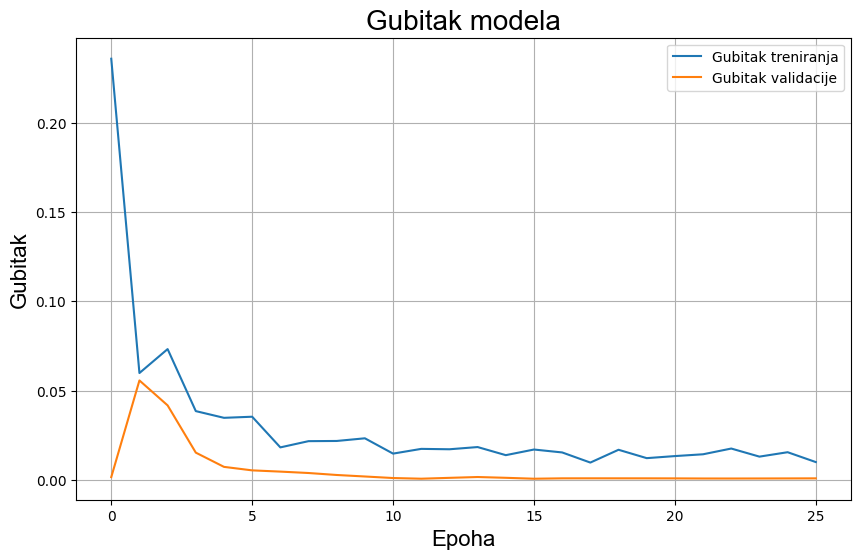

In [61]:
plt.figure(figsize=(10, 6))
titleFont = {'family':'arial','color':'black','size':20}
font = {'family':'arial','color':'black','size':16}
plt.plot(history.history['loss'], label='Gubitak treniranja')
plt.plot(history.history['val_loss'], label='Gubitak validacije')
plt.title('Gubitak modela', fontdict = titleFont)
plt.ylabel('Gubitak', fontdict = font)
plt.xlabel('Epoha', fontdict = font)
plt.grid()
plt.legend()
plt.show()

In [62]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE: {mse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R²: {r2:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
Test MSE: 0.0075
Test MAE: 0.0536
Test R²: 0.7555


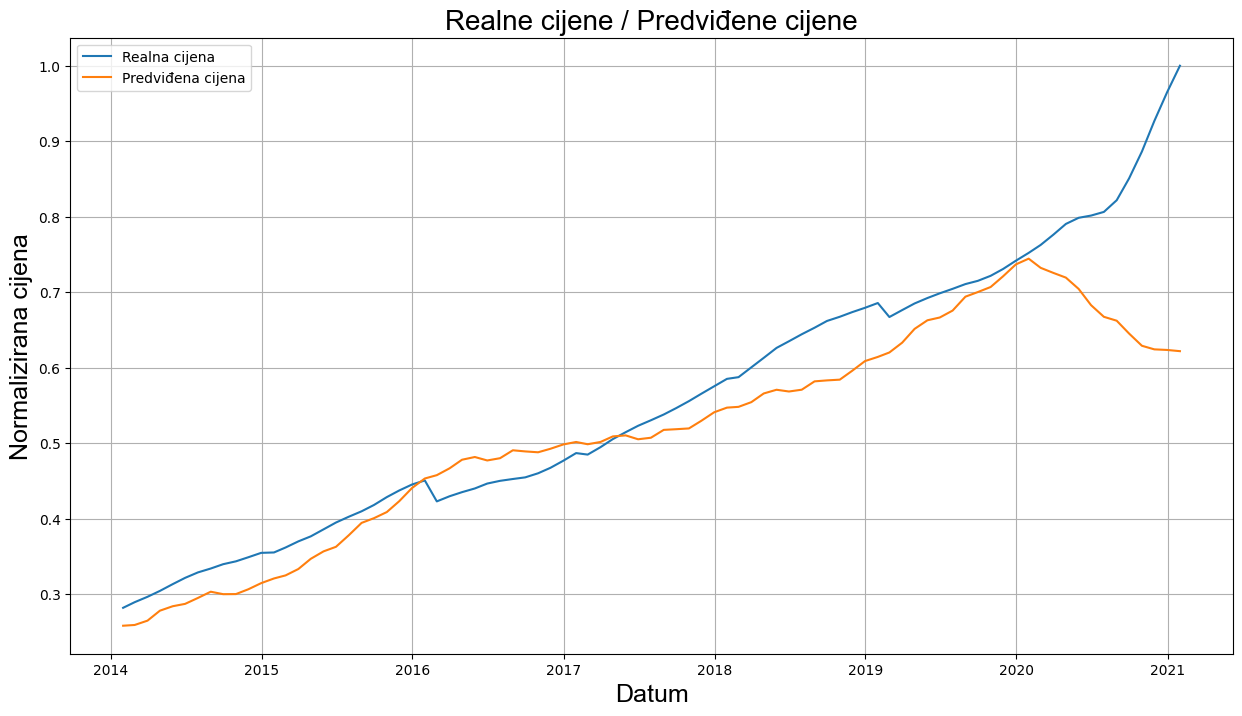

In [64]:
results_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred.flatten()
}, index=test_data.index[seq_length:])

titleFont = {'family':'arial','color':'black','size':20}
font = {'family':'arial','color':'black','size':18}
plt.figure(figsize=(15, 8))
plt.plot(results_df['Actual'], label='Realna cijena')
plt.plot(results_df['Predicted'], label='Predviđena cijena')
plt.title('Realne cijene / Predviđene cijene', fontdict = titleFont)
plt.ylabel('Normalizirana cijena', fontdict = font)
plt.xlabel('Datum', fontdict = font)
plt.grid()
plt.legend()
plt.show()